# 3주차: 평가와 임계값 설계

지난주에 학습한 모델(`runs/full/weights/best.pt`)을 채점한다. 위에서 아래로 순서대로 실행한다.

**규칙:** 임계값은 검증셋(val)에서만 정하고, 테스트셋(test)에는 그대로 적용한다. 테스트 결과를 보고 임계값을 다시 고치지 않는다.

`# 직접 타이핑`이라고 적힌 빈 셀은 직접 채운다.

## 준비: 경로와 상수

In [3]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ultralytics import YOLO
from ultralytics.engine.results import Results    # 타입 힌트용: 영상 한 장의 추론 결과

ROOT = Path.cwd().parent                      # 노트북의 작업 폴더가 scripts/ 이므로 한 단계 위가 프로젝트 폴더
DATA_DIR = ROOT / "data"
DATA_YAML = DATA_DIR / "data.yaml"
BEST_PT = ROOT / "runs" / "full" / "weights" / "best.pt"
OUT_DIR = Path("report/week_3/component")     # 그림·표를 저장할 곳
OUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES: list[str] = ["crack", "efflorescence", "spall_detach"]   # 클래스 ID 0, 1, 2
IMGSZ = 960
DEVICE = "mps"
CONF_FLOOR = 0.001                            # 추론할 때 남길 최소 신뢰도 (임계값 후보 중 가장 낮은 값)

for p in [DATA_YAML, BEST_PT]:
    if not p.exists():
        raise FileNotFoundError(p)
print("확인:", DATA_YAML)
print("확인:", BEST_PT)

확인: /Users/mac_mini/projects/detect_surface_defects/data/data.yaml
확인: /Users/mac_mini/projects/detect_surface_defects/runs/full/weights/best.pt


## 단계 1. 세그멘테이션 성능 (mask mAP)

모델이 칠한 영역이 정답 영역과 얼마나 겹치는지 테스트셋에서 잰다. 이 점수는 임계값과 상관없다.

In [4]:
# 직접 타이핑 (단계 1): 모델 불러오기, model.val 로 테스트셋 평가, 점수 출력

model = YOLO(str(BEST_PT))

results = model.val(
    data = str(DATA_YAML),
    split = "test",
    imgsz = IMGSZ,
    device = DEVICE,
    plots = True,
    project=str(ROOT / "runs"),
    name='week3_test'
)

print("mask mAP50 :", round(results.seg.map50, 4))
print("mask mAP50-95 :", round(results.seg.map, 4))
print("box mAP50 :", round(results.box.map50, 4))

for i, name in enumerate(CLASS_NAMES):
    print(
        name,
        "| mAP50", round(results.seg.ap50[i], 4),
        "| mAP50-95", round(results.seg.ap[i], 4),

    )


Ultralytics 8.4.212 🚀 Python-3.12.13 torch-2.14.0 MPS (Apple M4)
YOLOv8n-seg summary (fused): 86 layers, 3,385,609 parameters, 0 gradients, 11.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 573.6±106.1 MB/s, size: 193.2 KB)
val: Scanning /Users/mac_mini/projects/detect_surface_defects/data/labels/test.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 41.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.1it/s 1.4s1.1s
                   all         40         47      0.537      0.672       0.63      0.341      0.633      0.569      0.615      0.285
                 crack         13         14      0.364      0.643      0.501      0.244      0.457      0.542      0.407      0.111
         efflorescence         13         19      0.558      0.579      0.593        0.4      0.768      0.522      0.641      0.345
          spall_detach      

## 준비: 정답 목록과 예측 저장

- `load_split`: 라벨 파일을 읽어 사진마다 "어떤 결함이 있는지"(클래스 ID 집합)를 만든다.
- `predict_all`: 사진마다 모델을 **한 번만** 돌려 예측을 저장한다. 낮은 신뢰도의 예측도 버리지 않도록 `conf=CONF_FLOOR`를 준다(기본값은 0.25라서 그보다 낮은 임계값을 시험할 수 없다).

여기서는 검증셋만 추론한다. 테스트셋은 임계값을 정한 뒤 단계 4에서 추론한다.

In [5]:
# 영상 한 장의 예측: (클래스 ID 배열, 신뢰도 배열). 두 배열은 길이와 순서가 같다.
Pred = tuple[np.ndarray, np.ndarray]


def load_split(split: str) -> tuple[list[Path], list[set[int]]]:
    """split('val' 또는 'test')의 영상 경로 목록과, 영상별 정답 클래스 ID 집합 목록을 돌려준다."""
    paths: list[Path] = sorted((DATA_DIR / "images" / split).glob("*.jpg"))
    gts: list[set[int]] = []
    for p in paths:
        label = DATA_DIR / "labels" / split / (p.stem + ".txt")
        lines = label.read_text().splitlines() if label.exists() else []
        gts.append({int(line.split()[0]) for line in lines if line.strip()})   # 각 줄의 첫 숫자가 클래스 ID
    return paths, gts


def predict_all(model: YOLO, paths: list[Path]) -> tuple[list[Pred], list[Results]]:
    """영상마다 한 번 추론한다. 예측 (클래스 ID 배열, 신뢰도 배열) 목록과, 그림 그릴 때 쓸 결과 객체 목록을 돌려준다."""
    preds: list[Pred] = []
    results: list[Results] = []
    for p in paths:
        r: Results = model.predict(p, imgsz=IMGSZ, conf=CONF_FLOOR, device=DEVICE, verbose=False)[0].cpu()
        cid: np.ndarray = r.boxes.cls.numpy().astype(int)   # 예: [2, 2, 0]
        conf: np.ndarray = r.boxes.conf.numpy()             # 예: [0.91, 0.21, 0.03]
        preds.append((cid, conf))
        results.append(r)
    return preds, results


val_imgs, val_gts = load_split("val")
val_preds, val_results = predict_all(model, val_imgs)

print("검증셋 영상 수:", len(val_imgs))
for cid, name in enumerate(CLASS_NAMES):
    print(f"  {name}: 정답 ON 영상 {sum(cid in gt for gt in val_gts)}장")
print("첫 영상의 정답:", val_gts[0])
print("첫 영상의 예측 (클래스, 신뢰도) 앞 5개:", list(zip(val_preds[0][0][:5], val_preds[0][1][:5].round(3))))

검증셋 영상 수: 40
  crack: 정답 ON 영상 10장
  efflorescence: 정답 ON 영상 17장
  spall_detach: 정답 ON 영상 13장
첫 영상의 정답: {2}
첫 영상의 예측 (클래스, 신뢰도) 앞 5개: [(np.int64(2), np.float32(0.914)), (np.int64(2), np.float32(0.758)), (np.int64(2), np.float32(0.208)), (np.int64(2), np.float32(0.134)), (np.int64(2), np.float32(0.023))]


In [17]:
val_preds[0][1].shape

(15,)

## 단계 2. ON/OFF 평가 함수

영역이 정확한지는 따지지 않고, 영상에 그 결함이 **있는지 없는지**만 채점한다.

- 정답 ON: 그 클래스 라벨이 하나라도 있다.
- 예측 ON: 그 클래스 예측 중 신뢰도가 임계값 이상인 것이 하나라도 있다.

In [9]:
# 직접 타이핑 (단계 2): onoff(preds, gts, thr, cid_target) 함수
def onoff(preds: list[Pred], gts: list[set[int]], thr: float, cid_target: int) -> dict[str, float]:
    tp = fp = fn = tn = 0

    for(cid, conf), gt in zip(preds, gts):
        pred_on: bool = bool(((cid == cid_target) & (conf >= thr)).any())

        gt_on: bool = cid_target in gt

        if gt_on and pred_on:
            tp += 1
        elif not gt_on and pred_on:
            fp += 1
        elif gt_on and not pred_on:
            fn += 1
        else:
            tn += 1

    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0

    return {
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "precision": precision, "recall": recall, "f1": f1,
    }


In [10]:
# 직접 타이핑 (단계 2): thr=0.5 로 세 클래스에 대해 실행해 정상 동작 확인
for cid, name in enumerate(CLASS_NAMES):
    print(name, onoff(val_preds, val_gts, 0.5, cid))

crack {'tp': 8, 'fp': 1, 'fn': 2, 'tn': 29, 'precision': 0.8888888888888888, 'recall': 0.8, 'f1': 0.8421052631578948}
efflorescence {'tp': 7, 'fp': 0, 'fn': 10, 'tn': 23, 'precision': 1.0, 'recall': 0.4117647058823529, 'f1': 0.5833333333333334}
spall_detach {'tp': 11, 'fp': 2, 'fn': 2, 'tn': 25, 'precision': 0.8461538461538461, 'recall': 0.8461538461538461, 'f1': 0.8461538461538461}


## 단계 3. 검증셋에서 클래스별 임계값 탐색

후보 임계값마다 검증셋 F1을 구해 클래스별로 가장 높은 것을 고른다. 동점이면 낮은 임계값을 고른다(놓치는 것을 줄이는 쪽).

In [18]:
# 직접 타이핑 (단계 3): THRS, 클래스별 탐색, best 와 all_scores 만들기
THRS = [0.001, 0.004, 0.01, 0.02, 0.06, 0.1, 0.2, 0.3, 0.4, 0.5]

best: dict[str, float] = {}
all_scores: dict[str, list[float]] = {}

for cid, name in enumerate(CLASS_NAMES):
    scores = []

    for t in THRS:
        r = onoff(val_preds, val_gts, t, cid)
        scores.append(r['f1'])
        print(f"{name} | thr={t:.3f} | F1={r['f1']:.3f} | FP={r['fp']} | FN={r['fn']}")

    all_scores[name] = scores
    max_f1 = max(scores)
    best_idx = next(i for i, s in enumerate(scores) if s == max_f1)
    best[name] = THRS[best_idx]

    print(f">> {name} 선택 임계값: {THRS[best_idx]} (F1={max_f1:.3f})\n")

print("최종 임계값:", best)

crack | thr=0.001 | F1=0.488 | FP=21 | FN=0
crack | thr=0.004 | F1=0.588 | FP=14 | FN=0
crack | thr=0.010 | F1=0.667 | FP=10 | FN=0
crack | thr=0.020 | F1=0.667 | FP=8 | FN=1
crack | thr=0.060 | F1=0.818 | FP=3 | FN=1
crack | thr=0.100 | F1=0.857 | FP=2 | FN=1
crack | thr=0.200 | F1=0.857 | FP=2 | FN=1
crack | thr=0.300 | F1=0.857 | FP=2 | FN=1
crack | thr=0.400 | F1=0.857 | FP=2 | FN=1
crack | thr=0.500 | F1=0.842 | FP=1 | FN=2
>> crack 선택 임계값: 0.1 (F1=0.857)

efflorescence | thr=0.001 | F1=0.625 | FP=16 | FN=2
efflorescence | thr=0.004 | F1=0.700 | FP=9 | FN=3
efflorescence | thr=0.010 | F1=0.737 | FP=7 | FN=3
efflorescence | thr=0.020 | F1=0.765 | FP=4 | FN=4
efflorescence | thr=0.060 | F1=0.812 | FP=2 | FN=4
efflorescence | thr=0.100 | F1=0.812 | FP=2 | FN=4
efflorescence | thr=0.200 | F1=0.759 | FP=1 | FN=6
efflorescence | thr=0.300 | F1=0.741 | FP=0 | FN=7
efflorescence | thr=0.400 | F1=0.741 | FP=0 | FN=7
efflorescence | thr=0.500 | F1=0.583 | FP=0 | FN=10
>> efflorescence 선택 임계

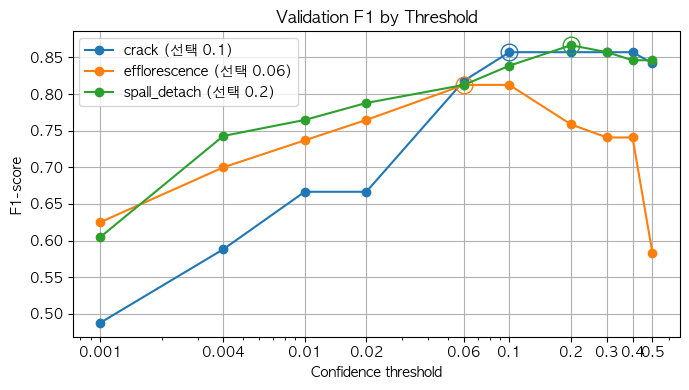

In [19]:
# F1 곡선 그림. 후보가 0.001~0.3 으로 넓게 퍼져 있어 가로축은 로그 눈금으로 그린다.
plt.rcParams["font.family"] = "AppleGothic"    # 범례의 한글이 깨지지 않게
plt.rcParams["axes.unicode_minus"] = False
fig, ax = plt.subplots(figsize=(7, 4))
for name in CLASS_NAMES:
    line, = ax.plot(THRS, all_scores[name], marker="o", label=f"{name} (선택 {best[name]})")
    i = THRS.index(best[name])
    ax.plot(THRS[i], all_scores[name][i], marker="o", markersize=12, markerfacecolor="none", color=line.get_color())
ax.set_xscale("log")
ax.set_xticks(THRS)
ax.set_xticklabels([str(t) for t in THRS])
ax.set_xlabel("Confidence threshold")
ax.set_ylabel("F1-score")
ax.set_title("Validation F1 by Threshold")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "val_threshold_f1.png", dpi=150)
plt.show()

pd.DataFrame(all_scores, index=THRS).rename_axis("threshold").to_csv(OUT_DIR / "val_threshold_f1.csv")

## 단계 4. 테스트셋 고정 적용

여기서 처음으로 테스트셋을 추론한다. 단계 3에서 정한 `best`를 **그대로** 쓴다.

In [20]:
test_imgs, test_gts = load_split("test")
test_preds, test_results = predict_all(model, test_imgs)

print("테스트셋 영상 수:", len(test_imgs))
for cid, name in enumerate(CLASS_NAMES):
    print(f"  {name}: 정답 ON 영상 {sum(cid in gt for gt in test_gts)}장")

테스트셋 영상 수: 40
  crack: 정답 ON 영상 13장
  efflorescence: 정답 ON 영상 13장
  spall_detach: 정답 ON 영상 14장


In [25]:
# 직접 타이핑 (단계 4): best 를 그대로 적용해 결과표 df 와 macro F1 만들기
rows: list[list] = []

for cid, name in enumerate(CLASS_NAMES):
    r = onoff(test_preds, test_gts, best[name], cid)
    rows.append([
        name, best[name],
        r['tp'], r['fp'], r['fn'], r['tn'],
        r['precision'], r['recall'], r['f1']
    ])

df = pd.DataFrame(
    rows,
    columns= ['class', 'threshold', 'TP', 'FP', 'FN', 'TN', 'precision', 'recall', 'f1']
)

print(df.round(3))
print("macro F1:", round(df["f1"].mean(), 3))

           class  threshold  TP  FP  FN  TN  precision  recall     f1
0          crack       0.10  11   1   2  26      0.917   0.846  0.880
1  efflorescence       0.06  13   3   0  24      0.812   1.000  0.897
2   spall_detach       0.20  13   2   1  24      0.867   0.929  0.897
macro F1: 0.891


In [26]:
df.to_csv(OUT_DIR / "test_onoff.csv", index=False)

## 단계 5. 오류 사례

테스트셋에서 틀린 영상을 클래스별로 뽑아 저장한다.

- FP(오탐): 정답에는 없는데 예측이 ON.
- FN(미탐): 정답에는 있는데 예측이 OFF.

그림은 왼쪽이 정답 폴리곤, 오른쪽이 예측이다. 예측은 클래스별 임계값 이상인 것만 그린다.
이 데이터는 영상마다 한 클래스만 라벨했으므로, FP는 "모델이 틀린 것"과 "라벨이 빠진 것"으로 나눠 본다.

In [27]:
GT_COLORS = {0: (0, 0, 255), 1: (0, 200, 0), 2: (255, 0, 0)}   # BGR: crack 빨강, efflorescence 초록, spall_detach 파랑


def draw_case(path: Path, split: str, result: Results, thr_by_name: dict[str, float]) -> np.ndarray:
    """왼쪽에 정답 폴리곤, 오른쪽에 임계값 이상인 예측을 그린 그림을 돌려준다."""
    img = cv2.imread(str(path))
    h, w = img.shape[:2]
    thick = max(2, round(max(h, w) / 400))

    left = img.copy()
    label = DATA_DIR / "labels" / split / (path.stem + ".txt")
    for line in label.read_text().splitlines():
        v = line.split()
        if not v:
            continue
        pts = (np.array(v[1:], dtype=float).reshape(-1, 2) * [w, h]).astype(np.int32)   # 0~1 좌표를 픽셀로
        cv2.polylines(left, [pts], True, GT_COLORS[int(v[0])], thick)

    cid = result.boxes.cls.numpy().astype(int)
    conf = result.boxes.conf.numpy()
    keep = [i for i in range(len(cid)) if conf[i] >= thr_by_name[CLASS_NAMES[cid[i]]]]
    right = result[keep].plot() if keep else img.copy()
    return np.hstack([left, right])


ERR_DIR = OUT_DIR / "error_cases"
rows = []
for cid, name in enumerate(CLASS_NAMES):
    (ERR_DIR / name).mkdir(parents=True, exist_ok=True)
    for old in (ERR_DIR / name).glob("*.jpg"):    # 다시 실행할 때 이전 그림이 남지 않게
        old.unlink()
    for p, gt, (pcid, pconf), r in zip(test_imgs, test_gts, test_preds, test_results):
        pred_on = bool(((pcid == cid) & (pconf >= best[name])).any())
        gt_on = cid in gt
        if pred_on == gt_on:
            continue
        kind = "FP" if pred_on else "FN"
        this = pconf[pcid == cid]
        rows.append({
            "class": name, "type": kind, "image": p.name,
            "gt_classes": ",".join(CLASS_NAMES[c] for c in sorted(gt)),
            "max_conf": round(float(this.max()), 4) if len(this) else 0.0,   # 이 클래스 예측 중 가장 높은 신뢰도
        })
        out = draw_case(p, "test", r, best)
        if out.shape[1] > 1600:                   # README에 넣기 좋게 가로 1600px로 줄여 저장
            k = 1600 / out.shape[1]
            out = cv2.resize(out, None, fx=k, fy=k, interpolation=cv2.INTER_AREA)
        cv2.imwrite(str(ERR_DIR / name / f"{kind}_{p.stem}.jpg"), out)

errors = pd.DataFrame(rows, columns=["class", "type", "image", "gt_classes", "max_conf"])
errors.to_csv(OUT_DIR / "test_errors.csv", index=False)
print(errors.groupby(["class", "type"]).size().unstack(fill_value=0))
errors

type           FN  FP
class                
crack           2   1
efflorescence   0   3
spall_detach    1   2


,class,type,image,gt_classes,max_conf
0,crack,FN,UCT011_2021_02_12_001_7770_jpg.rf.3b8c7b272fec...,crack,0.0115
1,crack,FN,URT005_2021_01_02_001_17812_jpg.rf.73a260d6850...,crack,0.0347
2,crack,FP,UWT015_2021_01_02_001_17710_jpg.rf.7572a104cda...,efflorescence,0.2790
3,efflorescence,FP,URT002_2021_01_07_001_23554.jpg,spall_detach,0.2318
4,efflorescence,FP,URT007_2022_01_14_001_6432.jpg,spall_detach,0.1438
5,efflorescence,FP,URT017_2020_02_08_001_24512_jpg.rf.c2fd9d2931d...,spall_detach,0.6176
6,spall_detach,FP,URT005_2021_01_02_001_9016_jpg.rf.cc3349867461...,crack,0.5134
7,spall_detach,FP,URT007_2022_01_13_001_10384_jpg.rf.acb53546883...,efflorescence,0.3090
8,spall_detach,FN,USU013_2022_04_16_005_2734_jpg.rf.af47edd2d0aa...,spall_detach,0.1737


## 마무리: README에 쓸 그림 복사

`runs/`는 git에 올리지 않으므로, README에 넣을 그림만 `report/week_3/component/`로 복사한다.


In [ ]:
import shutil

shutil.copy(ROOT / "runs" / "week3_test" / "MaskPR_curve.png", OUT_DIR / "test_mask_pr_curve.png")   # 단계 1의 PR 곡선
shutil.copy(ROOT / "runs" / "full" / "results.png", OUT_DIR / "train_results.png")                  # 본 학습 곡선
print(sorted(p.name for p in OUT_DIR.glob("*.png")))
